In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_style("whitegrid")

In [2]:
df = pd.read_csv("ai4i2020.csv")
print("Shape:", df.shape)
df.head()

Shape: (10000, 14)


,UDI,Product ID,Type,Air temperature [K],Process temperature [K],Rotational speed [rpm],Torque [Nm],Tool wear [min],Machine failure,TWF,HDF,PWF,OSF,RNF
0,1,M14860,M,298.1,308.6,1551,42.8,0,0,0,0,0,0,0
1,2,L47181,L,298.2,308.7,1408,46.3,3,0,0,0,0,0,0
2,3,L47182,L,298.1,308.5,1498,49.4,5,0,0,0,0,0,0
3,4,L47183,L,298.2,308.6,1433,39.5,7,0,0,0,0,0,0
4,5,L47184,L,298.2,308.7,1408,40.0,9,0,0,0,0,0,0


In [3]:
df.info()
df.describe().T

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 10000 entries, 0 to 9999
Data columns (total 14 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   UDI                      10000 non-null  int64  
 1   Product ID               10000 non-null  object 
 2   Type                     10000 non-null  object 
 3   Air temperature [K]      10000 non-null  float64
 4   Process temperature [K]  10000 non-null  float64
 5   Rotational speed [rpm]   10000 non-null  int64  
 6   Torque [Nm]              10000 non-null  float64
 7   Tool wear [min]          10000 non-null  int64  
 8   Machine failure          10000 non-null  int64  
 9   TWF                      10000 non-null  int64  
 10  HDF                      10000 non-null  int64  
 11  PWF                      10000 non-null  int64  
 12  OSF                      10000 non-null  int64  
 13  RNF                      10000 non-null  int64  
dtypes: float64(3), int64(9)

,count,mean,std,min,25%,50%,75%,max
UDI,10000.0,5000.50000,2886.895680,1.0,2500.75,5000.5,7500.25,10000.0
Air temperature [K],10000.0,300.00493,2.000259,295.3,298.30,300.1,301.50,304.5
Process temperature [K],10000.0,310.00556,1.483734,305.7,308.80,310.1,311.10,313.8
Rotational speed [rpm],10000.0,1538.77610,179.284096,1168.0,1423.00,1503.0,1612.00,2886.0
Torque [Nm],10000.0,39.98691,9.968934,3.8,33.20,40.1,46.80,76.6
Tool wear [min],10000.0,107.95100,63.654147,0.0,53.00,108.0,162.00,253.0
Machine failure,10000.0,0.03390,0.180981,0.0,0.00,0.0,0.00,1.0
TWF,10000.0,0.00460,0.067671,0.0,0.00,0.0,0.00,1.0
HDF,10000.0,0.01150,0.106625,0.0,0.00,0.0,0.00,1.0
PWF,10000.0,0.00950,0.097009,0.0,0.00,0.0,0.00,1.0


In [4]:
print("Missing values:\n", df.isnull().sum())
print("\nDuplicate rows:", df.duplicated().sum())
print("Duplicate Product ID:", df["Product ID"].duplicated().sum())

Missing values:
 UDI                        0
Product ID                 0
Type                       0
Air temperature [K]        0
Process temperature [K]    0
Rotational speed [rpm]     0
Torque [Nm]                0
Tool wear [min]            0
Machine failure            0
TWF                        0
HDF                        0
PWF                        0
OSF                        0
RNF                        0
dtype: int64

Duplicate rows: 0
Duplicate Product ID: 0


Machine failure
0    9661
1     339
Name: count, dtype: int64
Machine failure
0    96.61
1     3.39
Name: proportion, dtype: float64


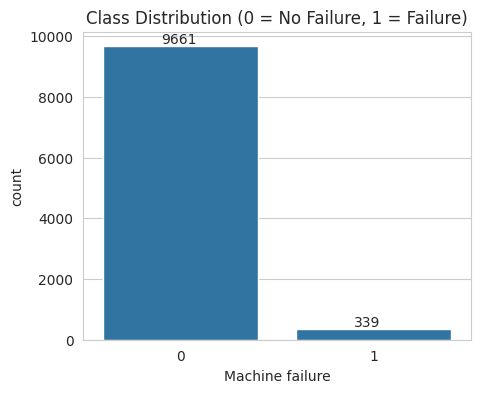

In [5]:
print(df["Machine failure"].value_counts())
print(df["Machine failure"].value_counts(normalize=True) * 100)

plt.figure(figsize=(5,4))
ax = sns.countplot(x="Machine failure", data=df)
for p in ax.patches:
    ax.annotate(int(p.get_height()), (p.get_x()+0.3, p.get_height()+100))
plt.title("Class Distribution (0 = No Failure, 1 = Failure)")
plt.show()

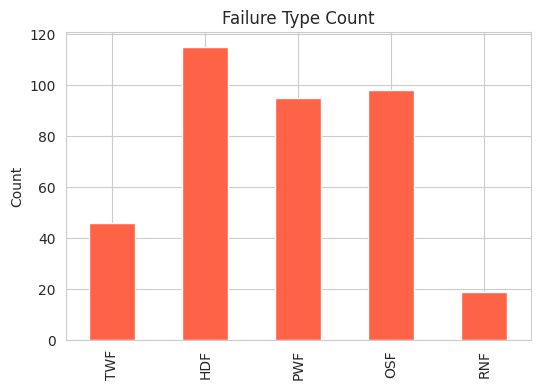

In [6]:
fail_types = ["TWF", "HDF", "PWF", "OSF", "RNF"]
df[fail_types].sum().plot(kind="bar", color="tomato", figsize=(6,4))
plt.title("Failure Type Count")
plt.ylabel("Count")
plt.show()

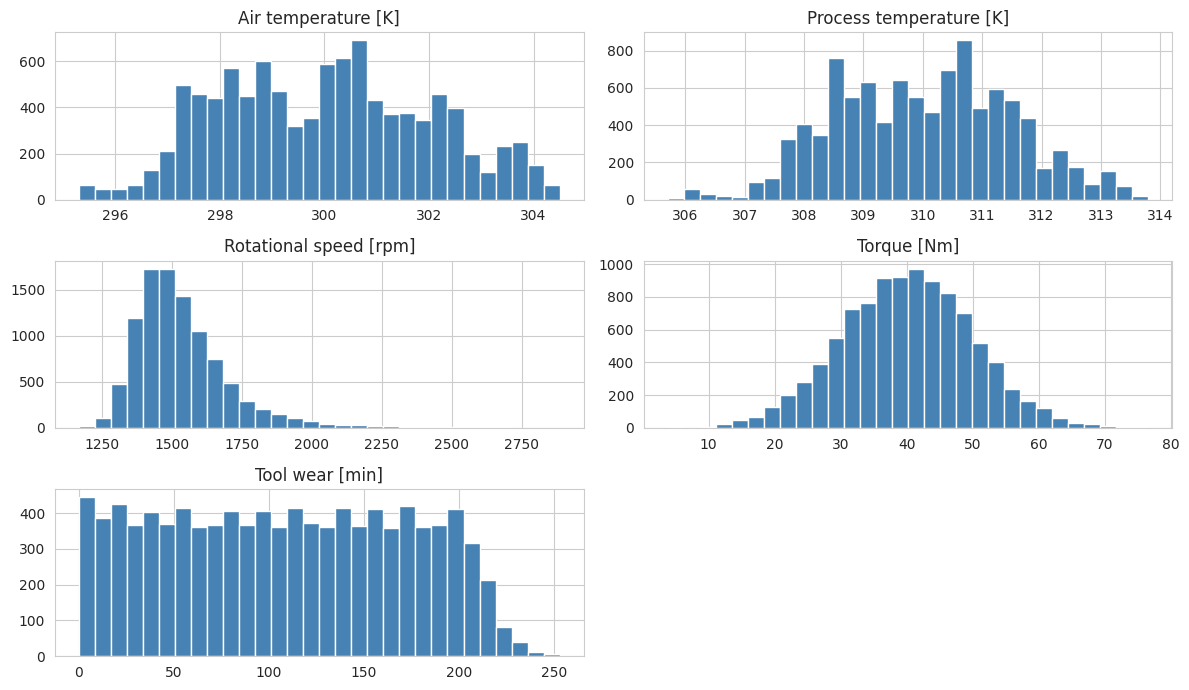

In [7]:
num_cols = ["Air temperature [K]", "Process temperature [K]",
            "Rotational speed [rpm]", "Torque [Nm]", "Tool wear [min]"]

df[num_cols].hist(bins=30, figsize=(12,7), color="steelblue")
plt.tight_layout()
plt.show()

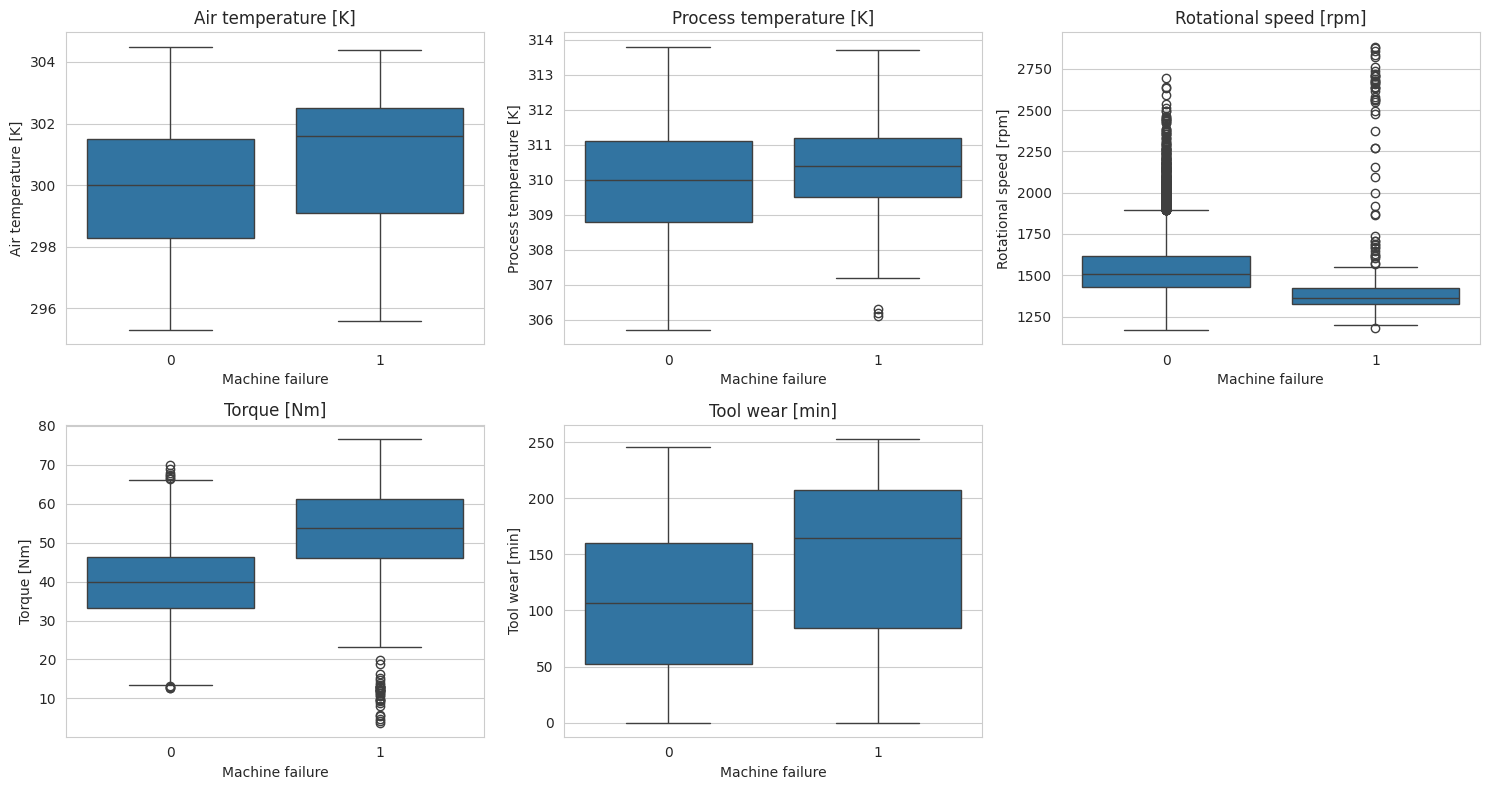

In [8]:
fig, axes = plt.subplots(2, 3, figsize=(15,8))
for ax, col in zip(axes.flatten(), num_cols):
    sns.boxplot(x="Machine failure", y=col, data=df, ax=ax)
    ax.set_title(col)
axes.flatten()[-1].axis("off")
plt.tight_layout()
plt.show()

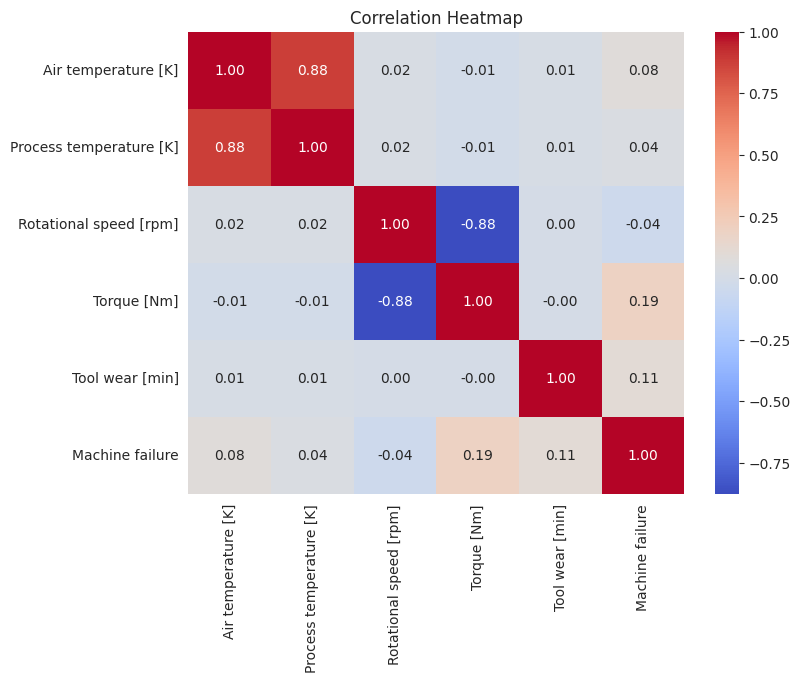

In [9]:
plt.figure(figsize=(8,6))
sns.heatmap(df[num_cols + ["Machine failure"]].corr(),
            annot=True, cmap="coolwarm", fmt=".2f")
plt.title("Correlation Heatmap")
plt.show()

In [10]:
print(df.groupby("Type")["Machine failure"].mean() * 100)

Type
H    2.093719
L    3.916667
M    2.769436
Name: Machine failure, dtype: float64


In [11]:
data = df.drop(columns=["UDI", "Product ID", "TWF", "HDF", "PWF", "OSF", "RNF"])

data = data.rename(columns={
    "Type": "type",
    "Air temperature [K]": "air_temp",
    "Process temperature [K]": "process_temp",
    "Rotational speed [rpm]": "rpm",
    "Torque [Nm]": "torque",
    "Tool wear [min]": "tool_wear",
    "Machine failure": "failure"
})

print(data.shape)
data.head()

(10000, 7)


,type,air_temp,process_temp,rpm,torque,tool_wear,failure
0,M,298.1,308.6,1551,42.8,0,0
1,L,298.2,308.7,1408,46.3,3,0
2,L,298.1,308.5,1498,49.4,5,0
3,L,298.2,308.6,1433,39.5,7,0
4,L,298.2,308.7,1408,40.0,9,0


In [12]:
type_map = {"L": 0, "M": 1, "H": 2}
data["type"] = data["type"].map(type_map)

print(data["type"].value_counts())
print("Null after encoding:", data["type"].isnull().sum())  # 0 হতে হবে

type
0    6000
1    2997
2    1003
Name: count, dtype: int64
Null after encoding: 0


In [13]:
data["temp_diff"] = data["process_temp"] - data["air_temp"]
data["power"] = data["torque"] * data["rpm"] * 2 * np.pi / 60  # ওয়াট

data[["temp_diff", "power"]].describe()

,temp_diff,power
count,10000.000000,10000.000000
mean,10.000630,6279.744953
std,1.001094,1067.418295
min,7.600000,1148.440610
25%,9.300000,5561.184484
50%,9.800000,6271.027344
75%,11.000000,7003.002724
max,12.100000,10469.923005


In [14]:
features = ["type", "air_temp", "process_temp", "rpm",
            "torque", "tool_wear", "temp_diff", "power"]

X = data[features]
y = data["failure"]

print("X shape:", X.shape)
print("y shape:", y.shape)

X shape: (10000, 8)
y shape: (10000,)


In [15]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

print("Train:", X_train.shape, "| Test:", X_test.shape)
print("Train failure %:", round(y_train.mean()*100, 2))
print("Test failure %:", round(y_test.mean()*100, 2))

Train: (8000, 8) | Test: (2000, 8)
Train failure %: 3.39
Test failure %: 3.4


In [16]:
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

print(pd.DataFrame(X_train_scaled, columns=features).describe().loc[["mean", "std"]].round(2))

      type  air_temp  process_temp  rpm  torque  tool_wear  temp_diff  power
mean   0.0       0.0           0.0  0.0    -0.0       -0.0       -0.0    0.0
std    1.0       1.0           1.0  1.0     1.0        1.0        1.0    1.0


In [17]:
from sklearn.utils.class_weight import compute_class_weight

classes = np.array([0, 1])
weights = compute_class_weight("balanced", classes=classes, y=y_train)
class_weight = {0: weights[0], 1: weights[1]}
print(class_weight)

{0: np.float64(0.51753137533963), 1: np.float64(14.760147601476016)}


In [19]:
import joblib, os
os.makedirs("artifacts", exist_ok=True)

joblib.dump(scaler, "artifacts/scaler.pkl")
joblib.dump(features, "artifacts/features.pkl")
joblib.dump(type_map, "artifacts/type_map.pkl")

print("saved successfully:", os.listdir("artifacts"))

saved successfully: ['type_map.pkl', 'scaler.pkl', 'features.pkl']


In [21]:
from sklearn.ensemble import RandomForestClassifier
import time

rf = RandomForestClassifier(
    n_estimators=200,
    max_depth=None,
    min_samples_leaf=2,
    class_weight=class_weight,
    random_state=42,
    n_jobs=-1
)

start = time.time()
rf.fit(X_train_scaled, y_train)
print(f"Random Forest trained completed ({time.time()-start:.1f} second)")

Random Forest trained completed (1.5 second)


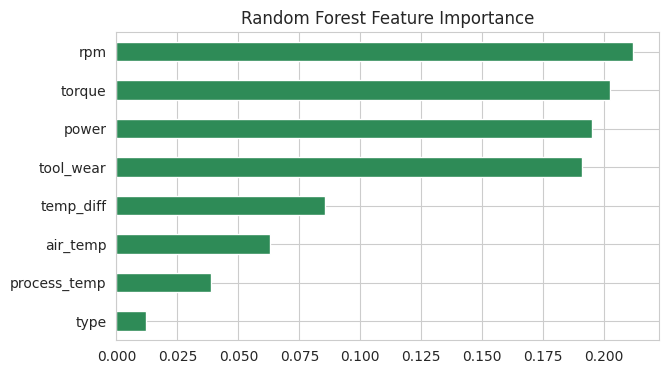

rpm             0.212
torque          0.203
power           0.195
tool_wear       0.191
temp_diff       0.086
air_temp        0.063
process_temp    0.039
type            0.012
dtype: float64


In [22]:
imp = pd.Series(rf.feature_importances_, index=features).sort_values()

imp.plot(kind="barh", figsize=(7,4), color="seagreen")
plt.title("Random Forest Feature Importance")
plt.show()

print(imp.sort_values(ascending=False).round(3))

In [23]:
import tensorflow as tf
from tensorflow.keras import layers, models, callbacks

tf.random.set_seed(42)
np.random.seed(42)

ann = models.Sequential([
    layers.Input(shape=(X_train_scaled.shape[1],)),
    layers.Dense(64, activation="relu"),
    layers.Dropout(0.3),
    layers.Dense(32, activation="relu"),
    layers.Dropout(0.2),
    layers.Dense(16, activation="relu"),
    layers.Dense(1, activation="sigmoid")
])

ann.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=0.001),
    loss="binary_crossentropy",
    metrics=["accuracy", tf.keras.metrics.Recall(name="recall"),
             tf.keras.metrics.Precision(name="precision")]
)

ann.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense (Dense)                   │ (None, 64)             │           576 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 32)             │         2,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 32)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 16)             │           528 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 1)              │            17 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 3,201 (12.50 KB)

 Trainable params: 3,201 (12.50 KB)

 Non-trainable params: 0 (0.00 B)

In [24]:
early_stop = callbacks.EarlyStopping(
    monitor="val_loss", patience=15, restore_best_weights=True
)

history = ann.fit(
    X_train_scaled, y_train,
    validation_split=0.2,
    epochs=100,
    batch_size=64,
    class_weight=class_weight,
    callbacks=[early_stop],
    verbose=1
)

print("stopped epoch:", len(history.history["loss"]))

Epoch 1/100
100/100 ━━━━━━━━━━━━━━━━━━━━ 4s 12ms/step - accuracy: 0.5736 - loss: 0.5937 - precision: 0.0623 - recall: 0.8287 - val_accuracy: 0.7750 - val_loss: 0.6459 - val_precision: 0.1216 - val_recall: 0.8909
Epoch 2/100
100/100 ━━━━━━━━━━━━━━━━━━━━ 1s 10ms/step - accuracy: 0.7738 - loss: 0.4981 - precision: 0.1091 - recall: 0.7963 - val_accuracy: 0.8100 - val_loss: 0.4969 - val_precision: 0.1327 - val_recall: 0.8182
Epoch 3/100
100/100 ━━━━━━━━━━━━━━━━━━━━ 1s 10ms/step - accuracy: 0.8077 - loss: 0.4312 - precision: 0.1282 - recall: 0.8102 - val_accuracy: 0.8450 - val_loss: 0.4084 - val_precision: 0.1614 - val_recall: 0.8364
Epoch 4/100
100/100 ━━━━━━━━━━━━━━━━━━━━ 1s 11ms/step - accuracy: 0.8322 - loss: 0.3843 - precision: 0.1501 - recall: 0.8519 - val_accuracy: 0.8700 - val_loss: 0.3441 - val_precision: 0.1852 - val_recall: 0.8182
Epoch 5/100
100/100 ━━━━━━━━━━━━━━━━━━━━ 1s 9ms/step - accuracy: 0.8345 - loss: 0.3820 - precision: 0.1508 - recall: 0.8426 - val_accuracy: 0.8512 - val

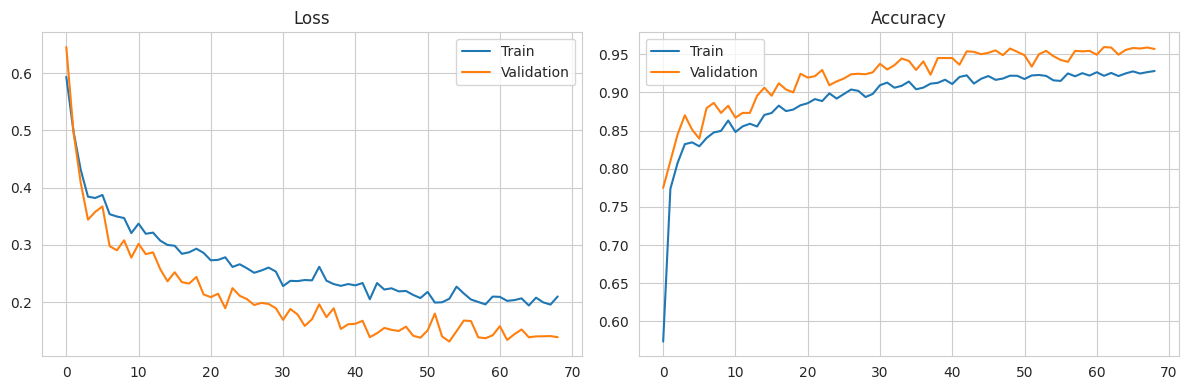

In [25]:
fig, ax = plt.subplots(1, 2, figsize=(12,4))

ax[0].plot(history.history["loss"], label="Train")
ax[0].plot(history.history["val_loss"], label="Validation")
ax[0].set_title("Loss"); ax[0].legend()

ax[1].plot(history.history["accuracy"], label="Train")
ax[1].plot(history.history["val_accuracy"], label="Validation")
ax[1].set_title("Accuracy"); ax[1].legend()

plt.tight_layout()
plt.show()

In [26]:
joblib.dump(rf, "artifacts/random_forest.pkl")
ann.save("artifacts/ann_model.keras")

print(os.listdir("artifacts"))

['ann_model.keras', 'type_map.pkl', 'random_forest.pkl', 'scaler.pkl', 'features.pkl']


In [27]:
from sklearn.metrics import (accuracy_score, precision_score, recall_score,
                             f1_score, confusion_matrix, classification_report,
                             roc_auc_score, roc_curve, precision_recall_curve,
                             average_precision_score)

# Random Forest
rf_prob = rf.predict_proba(X_test_scaled)[:, 1]
rf_pred = (rf_prob >= 0.5).astype(int)

# ANN
ann_prob = ann.predict(X_test_scaled).ravel()
ann_pred = (ann_prob >= 0.5).astype(int)

63/63 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step


In [28]:
def evaluate(name, y_true, y_pred, y_prob):
    return {
        "Model": name,
        "Accuracy": accuracy_score(y_true, y_pred),
        "Precision": precision_score(y_true, y_pred),
        "Recall": recall_score(y_true, y_pred),
        "F1-Score": f1_score(y_true, y_pred),
        "ROC-AUC": roc_auc_score(y_true, y_prob),
        "PR-AUC": average_precision_score(y_true, y_prob),
    }

results = pd.DataFrame([
    evaluate("Random Forest", y_test, rf_pred, rf_prob),
    evaluate("ANN", y_test, ann_pred, ann_prob),
]).set_index("Model").round(4)

results

,Accuracy,Precision,Recall,F1-Score,ROC-AUC,PR-AUC
Model,,,,,,
Random Forest,0.9890,0.9259,0.7353,0.8197,0.9773,0.8599
ANN,0.9505,0.3960,0.8676,0.5438,0.9795,0.7167


In [29]:
print("=== Random Forest ===")
print(classification_report(y_test, rf_pred, target_names=["No Failure", "Failure"]))

print("=== ANN ===")
print(classification_report(y_test, ann_pred, target_names=["No Failure", "Failure"]))

=== Random Forest ===
              precision    recall  f1-score   support

  No Failure       0.99      1.00      0.99      1932
     Failure       0.93      0.74      0.82        68

    accuracy                           0.99      2000
   macro avg       0.96      0.87      0.91      2000
weighted avg       0.99      0.99      0.99      2000

=== ANN ===
              precision    recall  f1-score   support

  No Failure       1.00      0.95      0.97      1932
     Failure       0.40      0.87      0.54        68

    accuracy                           0.95      2000
   macro avg       0.70      0.91      0.76      2000
weighted avg       0.97      0.95      0.96      2000



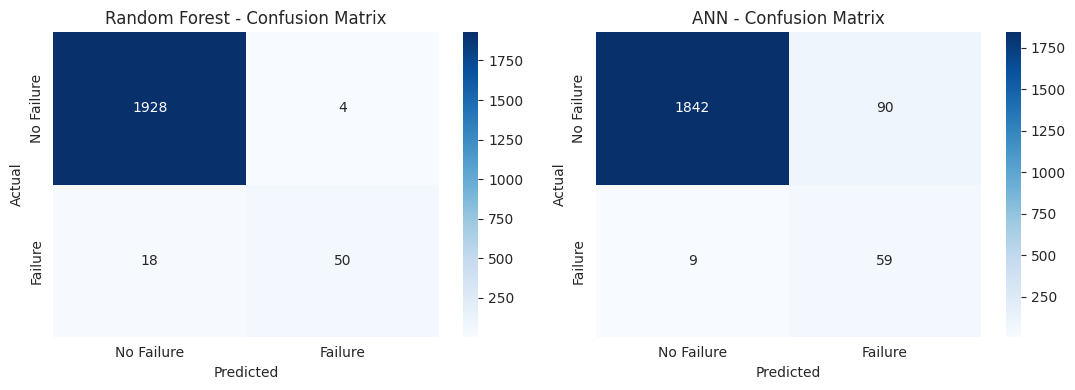

Random Forest: TN=1928, FP=4 (mistake preventation), FN=18 (missed failure), TP=50
ANN: TN=1842, FP=90 (mistake preventation), FN=9 (missed failure), TP=59


In [31]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4))

for ax, (name, pred) in zip(axes, [("Random Forest", rf_pred), ("ANN", ann_pred)]):
    cm = confusion_matrix(y_test, pred)
    sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", ax=ax,
                xticklabels=["No Failure", "Failure"],
                yticklabels=["No Failure", "Failure"])
    ax.set_title(f"{name} - Confusion Matrix")
    ax.set_xlabel("Predicted")
    ax.set_ylabel("Actual")

plt.tight_layout()
plt.show()

for name, pred in [("Random Forest", rf_pred), ("ANN", ann_pred)]:
    tn, fp, fn, tp = confusion_matrix(y_test, pred).ravel()
    print(f"{name}: TN={tn}, FP={fp} (mistake preventation), FN={fn} (missed failure), TP={tp}")

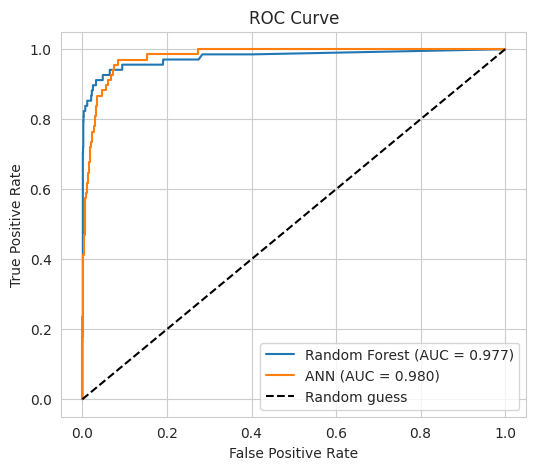

In [32]:
plt.figure(figsize=(6, 5))
for name, prob in [("Random Forest", rf_prob), ("ANN", ann_prob)]:
    fpr, tpr, _ = roc_curve(y_test, prob)
    plt.plot(fpr, tpr, label=f"{name} (AUC = {roc_auc_score(y_test, prob):.3f})")

plt.plot([0, 1], [0, 1], "k--", label="Random guess")
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC Curve")
plt.legend()
plt.show()

In [36]:
def threshold_table(name, prob, thresholds=(0.1, 0.2, 0.3, 0.4, 0.5, 0.6, 0.7)):
    rows = []
    for t in thresholds:
        pred = (prob >= t).astype(int)
        tn, fp, fn, tp = confusion_matrix(y_test, pred).ravel()
        rows.append({
            "Threshold": t,
            "Precision": round(precision_score(y_test, pred, zero_division=0), 3),
            "Recall": round(recall_score(y_test, pred), 3),
            "F1": round(f1_score(y_test, pred), 3),
            "FP (false alarm)": fp,
            "FN (missed)": fn,
        })
    print(f"=== {name} ===")
    display(pd.DataFrame(rows).set_index("Threshold"))

threshold_table("Random Forest", rf_prob)
threshold_table("ANN", ann_prob, thresholds=(0.5, 0.6, 0.7, 0.8, 0.9))

=== Random Forest ===


,Precision,Recall,F1,FP (false alarm),FN (missed)
Threshold,,,,,
0.1,0.384,0.926,0.543,101,5
0.2,0.592,0.853,0.699,40,10
0.3,0.812,0.824,0.818,13,12
0.4,0.903,0.824,0.862,6,12
0.5,0.926,0.735,0.820,4,18
0.6,0.958,0.676,0.793,2,22
0.7,0.946,0.515,0.667,2,33


=== ANN ===


,Precision,Recall,F1,FP (false alarm),FN (missed)
Threshold,,,,,
0.5,0.396,0.868,0.544,90,9
0.6,0.463,0.838,0.597,66,11
0.7,0.536,0.765,0.630,45,16
0.8,0.585,0.706,0.640,34,20
0.9,0.750,0.529,0.621,12,32


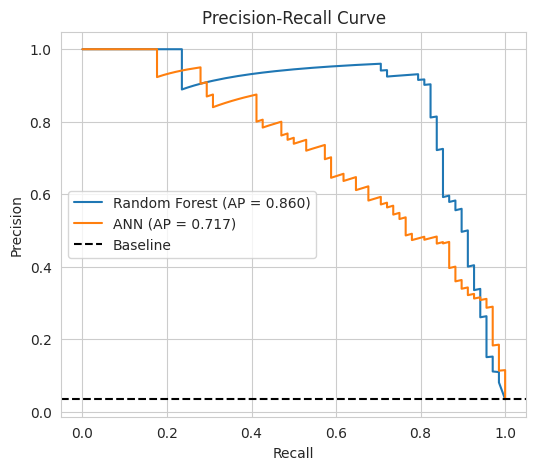

In [33]:
plt.figure(figsize=(6, 5))
for name, prob in [("Random Forest", rf_prob), ("ANN", ann_prob)]:
    p, r, _ = precision_recall_curve(y_test, prob)
    plt.plot(r, p, label=f"{name} (AP = {average_precision_score(y_test, prob):.3f})")

plt.axhline(y_test.mean(), color="k", linestyle="--", label="Baseline")
plt.xlabel("Recall")
plt.ylabel("Precision")
plt.title("Precision-Recall Curve")
plt.legend()
plt.show()

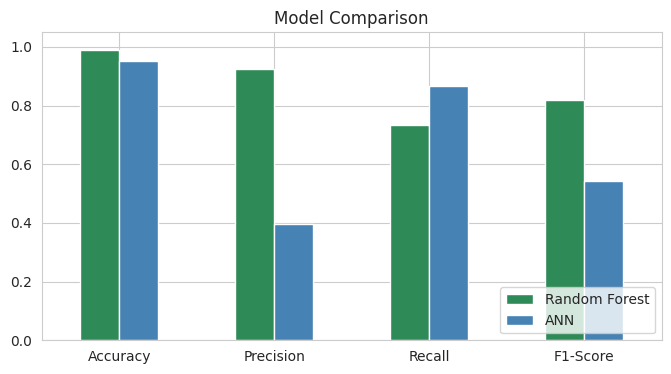

In [34]:
results[["Accuracy", "Precision", "Recall", "F1-Score"]].T.plot(
    kind="bar", figsize=(8, 4), rot=0, color=["seagreen", "steelblue"]
)
plt.title("Model Comparison")
plt.ylim(0, 1.05)
plt.legend(loc="lower right")
plt.show()

In [37]:
def best_threshold(name, prob):
    p, r, t = precision_recall_curve(y_test, prob)
    f1 = 2 * p[:-1] * r[:-1] / (p[:-1] + r[:-1] + 1e-9)
    i = f1.argmax()
    print(f"{name}: best threshold = {t[i]:.2f} | Precision = {p[i]:.3f} | Recall = {r[i]:.3f} | F1 = {f1[i]:.3f}")
    return t[i]

rf_t = best_threshold("Random Forest", rf_prob)
ann_t = best_threshold("ANN", ann_prob)

Random Forest: best threshold = 0.41 | Precision = 0.903 | Recall = 0.824 | F1 = 0.862
ANN: best threshold = 0.82 | Precision = 0.622 | Recall = 0.676 | F1 = 0.648


=== Final Model: Random Forest (threshold = 0.4) ===
              precision    recall  f1-score   support

  No Failure       0.99      1.00      1.00      1932
     Failure       0.90      0.82      0.86        68

    accuracy                           0.99      2000
   macro avg       0.95      0.91      0.93      2000
weighted avg       0.99      0.99      0.99      2000



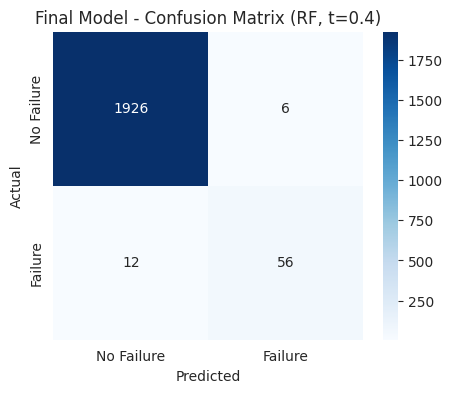

sklearn version: 1.6.1
['ann_model.keras', 'type_map.pkl', 'config.pkl', 'random_forest.pkl', 'scaler.pkl', 'features.pkl']


In [38]:
FINAL_T = 0.4
LOW_MAX = 0.2

final_pred = (rf_prob >= FINAL_T).astype(int)

print("=== Final Model: Random Forest (threshold = 0.4) ===")
print(classification_report(y_test, final_pred, target_names=["No Failure", "Failure"]))

cm = confusion_matrix(y_test, final_pred)
plt.figure(figsize=(5,4))
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues",
            xticklabels=["No Failure", "Failure"],
            yticklabels=["No Failure", "Failure"])
plt.title("Final Model - Confusion Matrix (RF, t=0.4)")
plt.xlabel("Predicted"); plt.ylabel("Actual")
plt.show()

config = {"model": "random_forest", "threshold": FINAL_T, "low_max": LOW_MAX}
joblib.dump(config, "artifacts/config.pkl")

import sklearn
print("sklearn version:", sklearn.__version__)   # noted
print(os.listdir("artifacts"))

In [40]:
!zip -r artifacts.zip artifacts
from google.colab import files
files.download("artifacts.zip")

updating: artifacts/ (stored 0%)
updating: artifacts/ann_model.keras (deflated 45%)
updating: artifacts/type_map.pkl (deflated 6%)
updating: artifacts/config.pkl (deflated 14%)
updating: artifacts/random_forest.pkl (deflated 72%)
updating: artifacts/scaler.pkl (deflated 34%)
updating: artifacts/features.pkl (deflated 11%)


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>